Customer Dataset:
   Annual_Income  Spending_Score
0             15              80
1             18              75
2             20              85
3             22              78
4             25              70

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Annual_Income   30 non-null     int64
 1   Spending_Score  30 non-null     int64
dtypes: int64(2)
memory usage: 612.0 bytes
None

Statistical Summary:
       Annual_Income  Spending_Score
count      30.000000       30.000000
mean       51.766667       44.366667
std        22.866454       23.216349
min        15.000000        5.000000
25%        32.750000       25.000000
50%        51.000000       42.500000
75%        69.500000       63.750000
max        95.000000       85.000000

Customer Groups:
    Annual_Income  Spending_Score  Customer_Group
0              15

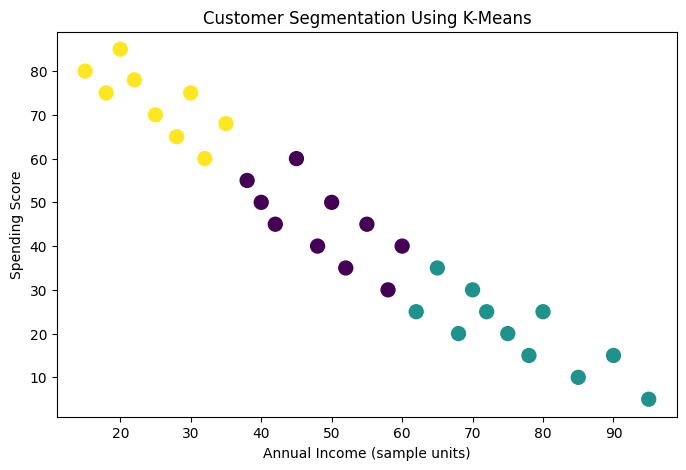


Customers in Each Group:
Customer_Group
1    11
0    10
2     9
Name: count, dtype: int64

Silhouette Score: 0.514

Task 3 Completed Successfully!


In [ ]:
#  CUSTOMER SEGMENTATION

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Create a sample customer dataset automatically
data = {
    'Annual_Income': [
        15, 18, 20, 22, 25, 28, 30, 32, 35, 38,
        40, 42, 45, 48, 50, 52, 55, 58, 60, 62,
        65, 68, 70, 72, 75, 78, 80, 85, 90, 95
    ],
    'Spending_Score': [
        80, 75, 85, 78, 70, 65, 75, 60, 68, 55,
        50, 45, 60, 40, 50, 35, 45, 30, 40, 25,
        35, 20, 30, 25, 20, 15, 25, 10, 15, 5
    ]
}

df = pd.DataFrame(data)

print("Customer Dataset:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

# Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(df)

# Apply K-Means clustering
model = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Customer_Group'] = model.fit_predict(X)

print("\nCustomer Groups:")
print(df)

# Visualize customer groups
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Income'],
    df['Spending_Score'],
    c=df['Customer_Group'],
    s=100
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (sample units)')
plt.ylabel('Spending Score')
plt.show()

# Count customers in each group
print("\nCustomers in Each Group:")
print(df['Customer_Group'].value_counts())

# Evaluate clustering
score = silhouette_score(X, df['Customer_Group'])
print("\nSilhouette Score:", round(score, 3))

print("\nTask 3 Completed Successfully!")